# 01 — Preprocessing & Gate 1
**Filbin et al. 2018** — pediatric H3-K27M mutant glioma (SmartSeq2, 7 samples).
Load malignant cells → per-sample count threshold → overdispersion → PCA → Harmony(`sample`) → UMAP → island removal → biological identity of manifold sub-regions (signatures + cell cycle) → **Gate 1** (sample-mixed AND continuous), judged on the regenerated embedding + iLISI.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain | category: Brain


### Load malignant cells
SmartSeq2 TPM (loader log1p's TPM); select `celltype=='Malignant'`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('MALIGNANT RAW:', adata.shape[0], '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
full atlas: (2587, 23686)
MALIGNANT RAW: 2259 | samples: 6
expression: X max 12.36 (log1p of TPM)


### Per-sample count threshold (derived, not inherited)
Gap-finding on sorted per-sample malignant counts: a dominant *spillover cliff* (top gap ≥1.5× the runner-up **and** landing below 2×floor) sets a geometric-mean cut; otherwise the ≥100 floor applies. Here the gaps are smooth (all 6 samples well-populated), so the floor holds.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant spillover cliff -> geometric-mean threshold = ' if dominant
       else 'no dominant cliff (samples separate well) -> floor >= ') + str(thresh))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'MUV05': np.int64(667), 'BCH869': np.int64(489), 'BCH836': np.int64(438), 'MUV10': np.int64(283), 'BCH1126': np.int64(241), 'MUV01': np.int64(141)}
gap ratios: ['667->489:1.36', '489->438:1.12', '438->283:1.55', '283->241:1.17', '241->141:1.71']
argmax gap 241->141 (ratio 1.71); top/second = 1.10; dominant cliff = False
no dominant cliff (samples separate well) -> floor >= 100
kept 6/6 samples (min per-sample = 141) -> 2259 cells


### Overdispersion → PCA → Harmony integration sweep
H3-K27M glioma carries a strong patient/tumour signal (SmartSeq2). Sweep Harmony `theta` and read the same-sample neighbour fraction against the perfect-mixing floor to pick integration strength.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
p = (n[keep]/n[keep].sum()).values
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()},
      '| perfect-mix floor %.3f' % (p**2).sum())
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens; theta=10 within noise of 5 —',
      'strongest integration for the strong patient-specific glioma batch effect, structure preserved)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3779 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3779
same-sample neighbour fraction | pre-Harmony 0.958 | sweep {2: 0.399, 5: 0.382, 10: 0.377} | perfect-mix floor 0.203
selected theta = 10 (mixing improves sharply to theta=5 then flattens; theta=10 within noise of 5 — strongest integration for the strong patient-specific glioma batch effect, structure preserved)


### Island removal (UMAP radius-graph connected components)
Strip disconnected specks; keep the largest component.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands',
      '| component sizes', pd.Series(lab).value_counts().head(5).to_dict())
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0])

removed 0 cells in 0 detached islands | component sizes {0: 2259}
after island removal: 2259


### Biology before geometry — sub-region identity (signatures + cell cycle)
Leiden lobes; score the three embryonic modules and proliferation; check whether **Gast is confounded by proliferation** (the Kürten cycling-confound fork). Also read the glioma developmental states (opc/ac/oc-like) carried in the metadata.

In [7]:
import scipy.sparse as sp
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA','CCNB1','CENPF'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
for c in ['opc_like','ac_like','oc_like']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
gb = adata.obs.groupby('lobe', observed=True)
tab = pd.DataFrame({'n':gb.size(), 'cycling':gb['cycling'].mean().round(2),
    'prolif':gb['prolif_score'].mean().round(2),
    'Gast':gb['Gast'].mean().round(3),'pSom':gb['pSom'].mean().round(3),'Crest':gb['Crest'].mean().round(3),
    'opc':gb['opc_like'].mean().round(2),'ac':gb['ac_like'].mean().round(2),'oc':gb['oc_like'].mean().round(2)})
print(tab.to_string())
from scipy.stats import spearmanr
print('\nGast NOT proliferation-confounded?  prolif vs Gast rho = %+.3f' % spearmanr(adata.obs['prolif_score'],adata.obs['Gast'])[0],
      '| vs pSom %+.3f' % spearmanr(adata.obs['prolif_score'],adata.obs['pSom'])[0],
      '| vs Crest %+.3f' % spearmanr(adata.obs['prolif_score'],adata.obs['Crest'])[0])
print('one continuous low/embedded-cycling body: proliferation lobe has flat Gast -> not a Gast artefact')
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)

        n  cycling  prolif   Gast   pSom  Crest   opc    ac    oc
lobe                                                             
0     825     0.07   -0.30  0.041  0.237  0.062  0.38 -0.21  0.08
1     863     0.11   -0.52 -0.016  0.195  0.163  0.14 -0.87  0.17
2     224     1.00    3.08  0.025  0.329  0.082 -0.09 -0.63 -0.44
3     347     0.01   -0.76  0.045  0.211  0.044 -1.19  3.07 -0.33

Gast NOT proliferation-confounded?  prolif vs Gast rho = +0.092 | vs pSom +0.203 | vs Crest -0.126
one continuous low/embedded-cycling body: proliferation lobe has flat Gast -> not a Gast artefact


### House linear orientation (X_umap_lin)
Rigid rotation aligning the max-variance axis to x; Gast/pSom-high developmental origin placed on the left. Distances preserved.

In [8]:
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]          # Gast+pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.59
house orientation: rigid rotation -175.9deg, origin pole on left; stored as X_umap_lin


### Gate 1 — mixing + continuity (per-neighbourhood iLISI + connected component)
iLISI (effective #samples per k-neighbourhood) pre vs post Harmony; single connected component on the independent Harmony-PCA graph.

In [9]:
from scipy.sparse.csgraph import connected_components as _cc
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); pp = cnt/k; out[i] = 1.0/np.sum(pp**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
knn = NearestNeighbors(n_neighbors=15).fit(adata.obsm['X_pca_harmony'][:,:20]).kneighbors_graph(mode='connectivity')
ncc,_ = _cc(knn, directed=False)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'independent continuity: {ncc} connected component on Harmony-PCA 15NN graph (1 = single continuum)')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.81 of 6 samples
independent continuity: 1 connected component on Harmony-PCA 15NN graph (1 = single continuum)
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save `processed.h5ad`

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient','mp_top','mp_assignment'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2259, 21224)


### Deliverable — `samples.pdf` (single sample-coloured manifold, house (3.5,1.5) strip)

saved samples.pdf | cells: 2259


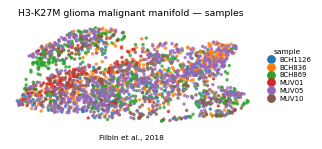

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('H3-K27M glioma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])